# Saudi Card Payments: Data Exploration and Dashboard Development
**Final Project, Unit 3: Individual Data Exploration & Dashboard Development**

Nouf, October 2026

**Contents**
1. Dataset
2. Problem definition
3. Data loading and structure
4. Data cleaning
5. Exploratory data analysis (univariate, bivariate and multivariate, hypotheses)
6. Insights summary
7. Limitations and recommendations

**Notes for reading this notebook**
- The data covers **point-of-sale (card) payments only**: cash, bank transfers and online payments are not included, so results describe card spending at physical terminals, not total consumer spending.
- The file holds three views of the same spending: national, sector and city. They are always analysed separately and never added together.
- **Average ticket** = total spending ÷ number of transactions (SAR per transaction). Values are nominal (not adjusted for inflation).
- The output of Step 4 is `clean_data.csv`, which is also the input of the Streamlit dashboard (`app.py`).

## Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
DATA_PATH = 'point-of-sale-transactions-by-sector-and-city.csv'

## Step 1: Dataset

- **Title:** Point of Sale Transactions by Sector and City
- **Source link:** https://data.kapsarc.org/explore/dataset/point-of-sale-transactions-by-sector-and-city/ (KAPSARC Data Portal, CSV export)
- **Original publisher:** the page labels the series "SAMA Weekly" (Saudi Central Bank); the original publisher is not stated explicitly on the page.
- **Description:** Weekly card payments made at point-of-sale terminals in Saudi Arabia, from 10 May 2020 to 6 July 2025 (270 weeks). For every week the file gives the value of transactions (thousand SAR) and the number of transactions (thousand), plus the weekly change of each, for 17 sectors and 11 cities. The raw file has 31,262 rows in a long format (one row per week, indicator, sector and city).
- **Why I chose it:** It is real Saudi data on consumer behaviour. It is weekly, so it can show events such as Ramadan, Eid and the pay cycle, and its sector and city breakdowns allow comparisons that can be tested against common beliefs (for example, that restaurants earn more in Ramadan).

## Step 2: Problem definition

**What is the dataset about?** Weekly card spending in Saudi Arabia: how much was paid (SAR), how many payments were made, and the average payment, for the whole country, for 17 sectors and for 11 cities.

**Main questions**
1. How did card spending, the number of payments and the average payment change from 2020 to 2025?
2. Which sectors and cities account for most of the spending, and are they big because of many payments or large payments?
3. Do restaurants and cafés spend more during Ramadan?
4. Is there a monthly pay cycle, with higher spending in the week salaries are paid?
5. Do Makkah and Madinah rise more than other cities in Ramadan, and how does Eid al-Fitr change spending?

**What I expected to find (before running the analysis)**
- Spending and payments grow over time, with the average payment falling as card use spreads.
- Restaurants and cafés rise in Ramadan, and the holy cities rise most.
- Spending is higher in the week salaries are paid and around Eid.

## Step 3: Data loading and structure

### 3.1 Load the raw file

In [ ]:
df = pd.read_csv(DATA_PATH, sep=';', encoding='utf-8-sig')
df.head()

,Starting date,Indicator,Sectors,City,value (Multiple units)
0,2025-07-06,Number of Transactions (In Thousand),Clothing and Footwear,Total,6723.0
1,2025-07-06,Number of Transactions (In Thousand),Education,Total,101.0
2,2025-07-06,Number of Transactions (In Thousand),Electronic & Electric Devices,Total,1412.0
3,2025-07-06,Number of Transactions (In Thousand),Hotels,Total,839.0
4,2025-07-06,Number of Transactions (In Thousand),Beverage and Food,Total,50562.0


### 3.2 Shape, data types, statistics and missing values

In [ ]:
df.shape

(31262, 5)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31262 entries, 0 to 31261
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Starting date           31262 non-null  str    
 1   Indicator               31262 non-null  str    
 2   Sectors                 31262 non-null  str    
 3   City                    31262 non-null  str    
 4   value (Multiple units)  31262 non-null  float64
dtypes: float64(1), str(4)
memory usage: 3.0 MB


In [ ]:
df.describe()

,value (Multiple units)
count,3.126200e+04
mean,2.857377e+05
std,1.157531e+06
min,-9.722462e+01
25%,-2.014915e+00
50%,1.033308e+02
75%,7.858275e+04
max,2.009805e+07


In [ ]:
df.isnull().sum()

Starting date             0
Indicator                 0
Sectors                   0
City                      0
value (Multiple units)    0
dtype: int64

**Insight:** The raw file has 31,262 rows and 5 columns, with no missing values. The values are numbers stored in one column called `value (Multiple units)`, so the unit depends on the indicator. `describe()` of that single column is therefore not meaningful on its own: it mixes thousands of SAR, thousands of transactions and percentages. The data has to be reshaped first (Step 4).

### 3.3 Understand the categories

In [ ]:
df['Indicator'].value_counts()

Indicator
Number of Transactions (In Thousand)       7830
Value of Transactions (In Thousand SAR)    7830
Number of Transactions Change %            7801
Value of Transactions Change %             7801
Name: count, dtype: int64

In [ ]:
df['Sectors'].value_counts()

Sectors
Total                                12936
Clothing and Footwear                 1078
Education                             1078
Electronic & Electric Devices         1078
Hotels                                1078
Beverage and Food                     1078
Miscellaneous Goods and Services      1078
Recreation and Culture                1078
Transportation                        1078
Construction & Building Materials     1078
Gas Stations                          1078
Telecommunication                     1078
Other                                 1078
Public Utilities                      1078
Furniture                             1078
Restaurants & Café                    1078
Health                                1078
Jewelry                               1078
Name: count, dtype: int64

In [ ]:
df['City'].value_counts()

City
Total       19404
DAMMAM       1078
JEDDAH       1078
RIYADH       1078
HAIL         1078
MAKKAH       1078
TABOUK       1078
BURAIDAH     1078
MADINA       1078
OTHER        1078
ABHA         1078
KHOBAR       1078
Name: count, dtype: int64

In [ ]:
# Is there any row that is both a specific sector and a specific city?
print((df['Sectors'].ne('Total') & df['City'].ne('Total')).sum(), 'rows with both a sector and a city')
print(df['Starting date'].min(), 'to', df['Starting date'].max(), '|', df['Starting date'].nunique(), 'weeks')

0 rows with both a sector and a city
2020-05-10 to 2025-07-06 | 270 weeks


**Insight:** There are four indicators: the value of transactions, the number of transactions, and the weekly change (%) of each. The change indicators have 29 fewer rows each, because the first week has no previous week. `Sectors` has 18 values (17 sectors plus `Total`) and `City` has 12 (11 cities plus `Total`). No row is both a specific sector and a specific city, so the file has three separate views: national (Total, Total), sectors (sector, Total) and cities (Total, city). It is not possible to know, for example, how much Riyadh spent on clothing.

## Step 4: Data cleaning

### 4.1 Rename columns, convert data types and remove duplicates

In [ ]:
df.columns = ['date', 'indicator', 'sector', 'city', 'value']
df['date'] = pd.to_datetime(df['date'])

key = ['date', 'indicator', 'sector', 'city']
print('Duplicate rows:', df.duplicated(key).sum())
df = df.drop_duplicates(key)
print('Rows after removing duplicates:', len(df))
df.dtypes

Duplicate rows: 0
Rows after removing duplicates: 31262


date         datetime64[us]
indicator               str
sector                  str
city                    str
value               float64
dtype: object

### 4.2 Clean the labels

In [ ]:
# Cities: title case first, then fix the specific spellings (exact matches)
df['city'] = df['city'].str.strip().str.title()
df['city'] = df['city'].replace({'Tabouk': 'Tabuk',
                                 'Madina': 'Madinah',
                                 'Other': 'Other cities'})

# Sectors: exact match, so 'Other' becomes 'Other sector'
df['sector'] = df['sector'].str.strip().replace({'Other': 'Other sector'})

print("Unique Cities:", sorted(df['city'].unique()))
print("Unique Sectors:", sorted(df['sector'].unique()))

Unique Cities: ['Abha', 'Buraidah', 'Dammam', 'Hail', 'Jeddah', 'Khobar', 'Madinah', 'Makkah', 'Other cities', 'Riyadh', 'Tabuk', 'Total']
Unique Sectors: ['Beverage and Food', 'Clothing and Footwear', 'Construction & Building Materials', 'Education', 'Electronic & Electric Devices', 'Furniture', 'Gas Stations', 'Health', 'Hotels', 'Jewelry', 'Miscellaneous Goods and Services', 'Other sector', 'Public Utilities', 'Recreation and Culture', 'Restaurants & Café', 'Telecommunication', 'Total', 'Transportation']


**Insight:** Three city spellings were standardised (`Tabouk` to `Tabuk`, `Madina` to `Madinah`, `Other` to `Other cities`) and the sector `Other` became `Other sector`, so the two "Other" groups cannot be confused.

### 4.3 Reshape from long to wide and handle missing values

In [ ]:
# 1. Reshape: indicator values become columns
df_wide = df.pivot_table(
    index=['date', 'sector', 'city'],
    columns='indicator',
    values='value',
    aggfunc='first'
).reset_index()

# 2. Clean column names
df_wide.columns.name = None
df_wide = df_wide.rename(columns={
    'Value of Transactions (In Thousand SAR)': 'value_sar_k',
    'Number of Transactions (In Thousand)': 'transactions_k',
    'Value of Transactions Change %': 'value_change_pct',
    'Number of Transactions Change %': 'transactions_change_pct'
})

# 3. Split into three tables
national  = df_wide[(df_wide['sector'] == 'Total') & (df_wide['city'] == 'Total')].reset_index(drop=True)
by_sector = df_wide[(df_wide['city'] == 'Total') & (df_wide['sector'] != 'Total')].reset_index(drop=True)
by_city   = df_wide[(df_wide['sector'] == 'Total') & (df_wide['city'] != 'Total')].reset_index(drop=True)

# 4. Verify
print(f"National shape: {national.shape}")
print(f"By Sector shape: {by_sector.shape}")
print(f"By City shape: {by_city.shape}")
print(list(national.columns))

National shape: (270, 7)
By Sector shape: (4590, 7)
By City shape: (2970, 7)
['date', 'sector', 'city', 'transactions_k', 'transactions_change_pct', 'value_sar_k', 'value_change_pct']


In [ ]:
# Missing values after the reshape
print(df_wide.isnull().sum())

date                        0
sector                      0
city                        0
transactions_k              0
transactions_change_pct    29
value_sar_k                 0
value_change_pct           29
dtype: int64


**Insight:** The only missing values are the weekly change (%) of the first week of each series (29 series, so 29 missing values in each change column). They are not errors: there is no earlier week to compare with. They were left as `NaN` instead of being filled, because any fill value would be invented.

### 4.4 Derived columns

Ramadan periods follow the dates announced in Saudi Arabia (2021: 13 Apr to 12 May, 2022: 2 Apr to 1 May, 2023: 23 Mar to 20 Apr, 2024: 11 Mar to 9 Apr, 2025: 1 Mar to 29 Mar). A week counts as a Ramadan week when at least 4 of its 7 days fall inside Ramadan. A **salary week** is a week that contains the 27th of a month: this is an assumption about the pay date, not a verified payday.

In [ ]:
# 4.4 Derived columns (feature engineering)

# Ramadan periods (start, end), Saudi Arabia
ramadan_periods = [
    ('2020-04-24', '2020-05-23'),
    ('2021-04-13', '2021-05-12'),
    ('2022-04-02', '2022-05-01'),
    ('2023-03-23', '2023-04-20'),
    ('2024-03-11', '2024-04-09'),
    ('2025-03-01', '2025-03-29'),
]

def is_ramadan_week(week_start):
    """1 if at least 4 of the week's 7 days fall inside Ramadan, else 0."""
    days = pd.date_range(week_start, periods=7)
    in_ramadan = sum(
        any(pd.Timestamp(start) <= d <= pd.Timestamp(end) for start, end in ramadan_periods)
        for d in days
    )
    return int(in_ramadan >= 4)

def is_salary_week(week_start):
    """1 if the 27th of a month falls inside the week (assumed salary day)."""
    return int(any(d.day == 27 for d in pd.date_range(week_start, periods=7)))

for t in (national, by_sector, by_city):
    t['avg_ticket_sar'] = t['value_sar_k'] / t['transactions_k']
    t['year'] = t['date'].dt.year
    t['month'] = t['date'].dt.month
    t['week_of_year'] = t['date'].dt.isocalendar().week.astype(int)
    t['is_ramadan'] = t['date'].apply(is_ramadan_week)
    t['is_salary_week'] = t['date'].apply(is_salary_week)

# Verify
print(national.groupby('year')[['is_ramadan', 'is_salary_week']].sum())
print(national['avg_ticket_sar'].describe().round(1))
print(national.shape, by_sector.shape, by_city.shape)

      is_ramadan  is_salary_week
year                            
2020           2               7
2021           5              12
2022           4              12
2023           4              12
2024           4              12
2025           4               6
count    270.0
mean      80.0
std       21.2
min       53.6
25%       65.1
50%       72.6
75%       88.7
max      170.9
Name: avg_ticket_sar, dtype: float64
(270, 13) (4590, 13) (2970, 13)


### 4.5 Save the cleaned data

In [ ]:
# 4.5 Save the cleaned data

# Add a level and a name column so the three tables can live in one file
national['level'],  national['name']  = 'national', 'Saudi Arabia'
by_sector['level'], by_sector['name'] = 'sector',   by_sector['sector']
by_city['level'],   by_city['name']   = 'city',     by_city['city']

feature_cols = [
    'date', 'level', 'name',
    'value_sar_k', 'transactions_k', 'avg_ticket_sar',
    'value_change_pct', 'transactions_change_pct',
    'year', 'month', 'week_of_year', 'is_ramadan', 'is_salary_week'
]

clean_data = pd.concat(
    [national[feature_cols], by_sector[feature_cols], by_city[feature_cols]],
    ignore_index=True
)

clean_data.to_csv('clean_data.csv', index=False)

# Verify by reading it back
check = pd.read_csv('clean_data.csv', parse_dates=['date'])
print(check.shape)
print(check['level'].value_counts())
print(check.isnull().sum())
check.head()

(7830, 13)
level
sector      4590
city        2970
national     270
Name: count, dtype: int64
date                        0
level                       0
name                        0
value_sar_k                 0
transactions_k              0
avg_ticket_sar              0
value_change_pct           29
transactions_change_pct    29
year                        0
month                       0
week_of_year                0
is_ramadan                  0
is_salary_week              0
dtype: int64


,date,level,name,value_sar_k,transactions_k,avg_ticket_sar,value_change_pct,transactions_change_pct,year,month,week_of_year,is_ramadan,is_salary_week
0,2020-05-10,national,Saudi Arabia,6002585.0,38132.0,157.415950,NaN,NaN,2020,5,19,1,0
1,2020-05-17,national,Saudi Arabia,6491277.0,41324.0,157.082494,8.141359,8.370922,2020,5,20,1,0
2,2020-05-24,national,Saudi Arabia,3253178.0,29082.0,111.862252,-49.883852,-29.624431,2020,5,21,0,1
3,2020-05-31,national,Saudi Arabia,7854373.0,50281.0,156.209562,141.436927,72.893886,2020,5,22,0,0
4,2020-06-07,national,Saudi Arabia,7295830.0,48209.0,151.337510,-7.111236,-4.120841,2020,6,23,0,0


### 4.6 Cleaning summary

| Step | What I found | What I did |
|---|---|---|
| Missing values | None in the raw file. After the reshape, the first week of each series has no weekly change (29 per change column) | Kept as `NaN` (not filled) |
| Duplicates | None on (date, indicator, sector, city) | Check kept in the code; `drop_duplicates` removes any |
| Data types | `date` was text | Converted to datetime |
| Column names | Long names, one value column with mixed units | Renamed; indicators became columns (`value_sar_k`, `transactions_k`, `value_change_pct`, `transactions_change_pct`) |
| Labels | Inconsistent city names and a generic `Other` in both sectors and cities | Standardised spellings; `Other sector` and `Other cities` |
| Structure | Three views of the same spending mixed in one file | Split into national, sector and city, then stacked into one file with `level` and `name` columns |
| New columns | Needed for analysis | `avg_ticket_sar`, `year`, `month`, `week_of_year`, `is_ramadan`, `is_salary_week` |

**Output:** `clean_data.csv` (7,830 rows, 13 columns). It is loaded again at the start of Step 5 and is the input of the Streamlit dashboard.

## Step 5: Exploratory data analysis

The analysis starts from the saved file, exactly as the dashboard does. The three views (national, sector, city) are always analysed separately: adding them would count the same spending three times.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('clean_data.csv', parse_dates=['date'])
national = df[df['level'] == 'national'].copy()
sector = df[df['level'] == 'sector'].copy()
city = df[df['level'] == 'city'].copy()
print(df.shape, national.shape, sector.shape, city.shape)

(7830, 13) (270, 13) (4590, 13) (2970, 13)


In [ ]:
national.head()

,date,level,name,value_sar_k,transactions_k,avg_ticket_sar,value_change_pct,transactions_change_pct,year,month,week_of_year,is_ramadan,is_salary_week
0,2020-05-10,national,Saudi Arabia,6002585.0,38132.0,157.415950,NaN,NaN,2020,5,19,1,0
1,2020-05-17,national,Saudi Arabia,6491277.0,41324.0,157.082494,8.141359,8.370922,2020,5,20,1,0
2,2020-05-24,national,Saudi Arabia,3253178.0,29082.0,111.862252,-49.883852,-29.624431,2020,5,21,0,1
3,2020-05-31,national,Saudi Arabia,7854373.0,50281.0,156.209562,141.436927,72.893886,2020,5,22,0,0
4,2020-06-07,national,Saudi Arabia,7295830.0,48209.0,151.337510,-7.111236,-4.120841,2020,6,23,0,0


### 5.1 Scope of the analysis

The data is weekly and covers 10 May 2020 to 6 July 2025. The number of weeks in each year shows which years are complete.

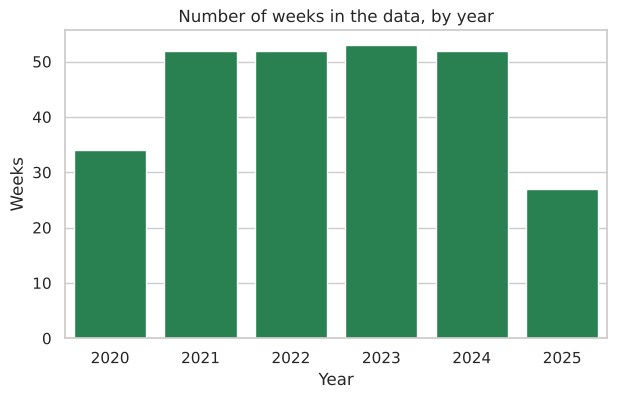

In [ ]:
FULL_YEARS = [2021, 2022, 2023, 2024]

plt.figure(figsize=(7, 4))
sns.countplot(data=national, x='year', color='#1a8f4e')
plt.title('Number of weeks in the data, by year')
plt.xlabel('Year')
plt.ylabel('Weeks')
plt.show()

**Insight:** 2020 starts in May (34 weeks) and 2025 ends in July (27 weeks), while 2021 to 2024 have 52 or 53 weeks each. Annual and monthly comparisons therefore use only the four full years (2021-2024, `FULL_YEARS`). 2020 and 2025 stay in the time-series charts.

### 5.2 Univariate analysis

#### 5.2.1 Summary statistics

In [ ]:
national[['value_sar_k', 'transactions_k', 'avg_ticket_sar', 'value_change_pct']].describe().round(1)

,value_sar_k,transactions_k,avg_ticket_sar,value_change_pct
count,270.0,270.0,270.0,269.0
mean,10880639.9,147356.6,80.0,2.1
std,2390378.4,51438.5,21.2,20.1
min,3253178.0,29082.0,53.6,-49.9
25%,9160361.2,106558.5,65.1,-9.0
50%,10883853.5,153759.0,72.6,-2.8
75%,12300366.0,190779.8,88.7,11.3
max,20098053.0,245751.0,170.9,141.4


#### 5.2.2 Histograms

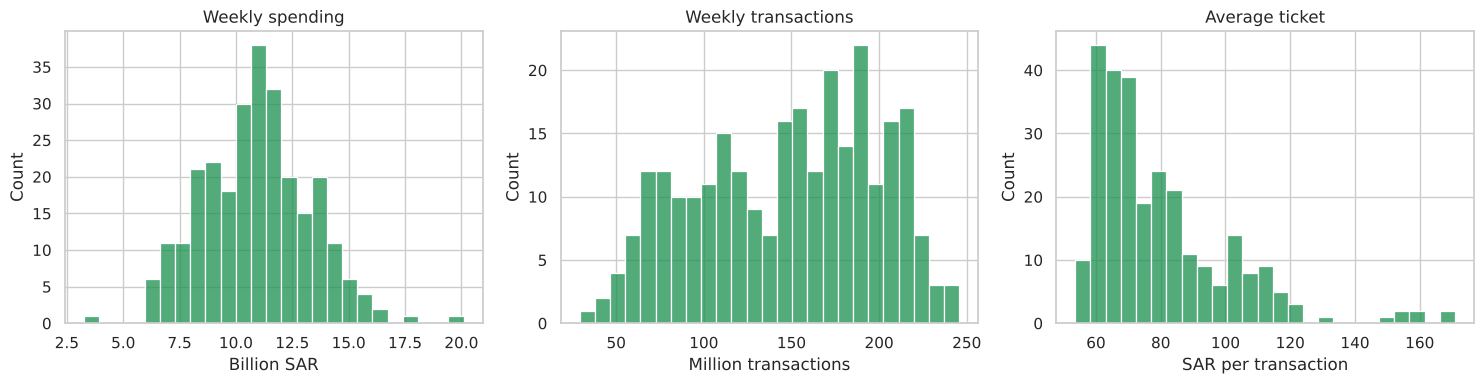

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(national['value_sar_k'] / 1e6, bins=25, ax=axes[0], color='#1a8f4e')
axes[0].set_title('Weekly spending')
axes[0].set_xlabel('Billion SAR')
sns.histplot(national['transactions_k'] / 1e3, bins=25, ax=axes[1], color='#1a8f4e')
axes[1].set_title('Weekly transactions')
axes[1].set_xlabel('Million transactions')
sns.histplot(national['avg_ticket_sar'], bins=25, ax=axes[2], color='#1a8f4e')
axes[2].set_title('Average ticket')
axes[2].set_xlabel('SAR per transaction')
plt.tight_layout()
plt.show()

**Insight:** Weekly spending is roughly symmetric around SAR 10.9 billion (mean and median are almost equal, range SAR 3.3 to 20.1 billion). Weekly transactions have a longer tail toward low values (median 154 million, mean 147 million), because the early weeks of 2020 had few transactions. The average ticket is skewed to the right: half of the weeks are between SAR 65 and SAR 89, but 48 weeks are above SAR 100, almost all between May 2020 and May 2021.

#### 5.2.3 Boxplots

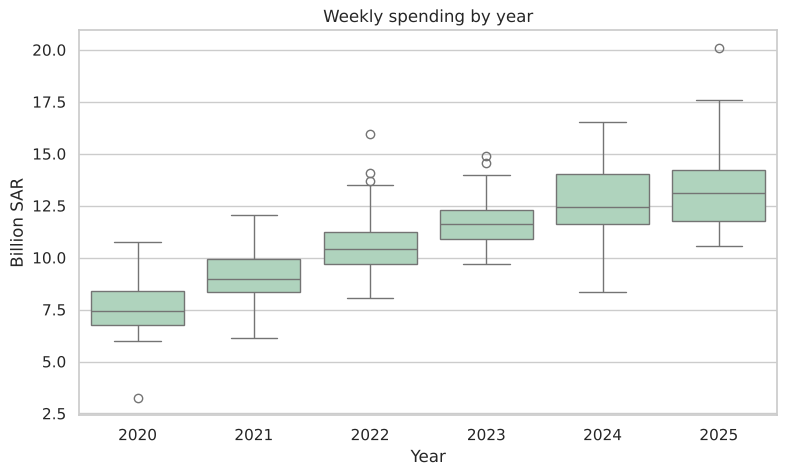

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=national, x='year', y=national['value_sar_k'] / 1e6, color='#a9d9bb')
plt.title('Weekly spending by year')
plt.xlabel('Year')
plt.ylabel('Billion SAR')
plt.show()

**Insight:** The median week rises every year, from about SAR 7.4 billion in 2020 to about SAR 13.1 billion in 2025. The middle halves of the weeks (the boxes) of years two apart do not overlap (for example 2021 and 2023), while 2024 and 2025 overlap almost completely, so growth looks slower in the latest year (2025 covers only January to July). The spread inside a year is similar (about SAR 5 to 8 billion between the lowest and highest week), except 2025 (about 10 billion), whose highest week (about SAR 20 billion, March 2025) is far above its box.

#### 5.2.4 Weekly change and outliers

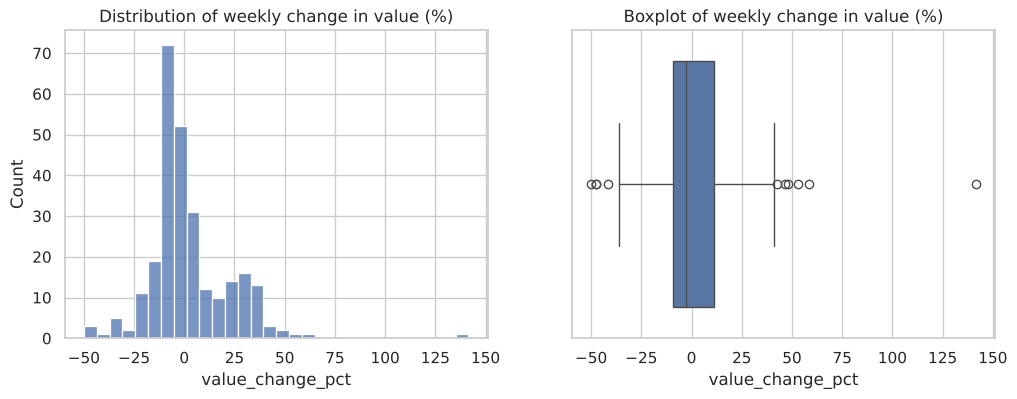

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(national['value_change_pct'], bins=30, ax=axes[0])
axes[0].set_title('Distribution of weekly change in value (%)')
sns.boxplot(x=national['value_change_pct'], ax=axes[1])
axes[1].set_title('Boxplot of weekly change in value (%)')
plt.show()

**Insight:** The weekly change in spending is centered near zero (median -2.8%, mean +2.1%) and half of the weeks fall between -9% and +11%. The distribution has a long right tail, with rare jumps of up to +141%.

In [ ]:
q1, q3 = national['value_change_pct'].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = national[(national['value_change_pct'] < q1 - 1.5 * iqr) | (national['value_change_pct'] > q3 + 1.5 * iqr)]
print(len(outliers), 'outlier weeks out of', national['value_change_pct'].notna().sum())
outliers[['date', 'value_sar_k', 'value_change_pct', 'is_ramadan']]

10 outlier weeks out of 269


,date,value_sar_k,value_change_pct,is_ramadan
2,2020-05-24,3253178.0,-49.883852,0
3,2020-05-31,7854373.0,141.436927,0
50,2021-04-25,10731129.0,46.698964,1
63,2021-07-25,9713267.0,58.615881,0
102,2022-04-24,15971636.0,53.213622,1
103,2022-05-01,8402910.0,-47.388546,0
111,2022-06-26,13433950.0,42.584355,0
214,2024-06-16,8343012.0,-41.390438,0
215,2024-06-23,12349544.0,48.022609,0
255,2025-03-30,10540296.0,-47.555636,0


- Ten weeks fall outside the usual range of weekly change (below -39.5% or above +41.8%). Nine of them are in or next to Ramadan, Eid al-Fitr or Eid al-Adha weeks, or in May 2020, and one is not clearly linked to a holiday. They are real weeks and none was removed.

### 5.3 National overview

#### 5.3.1 Spending and transactions over time

In [ ]:
yearly = national.groupby('year').agg(value_bn=('value_sar_k', 'mean'), transactions_m=('transactions_k', 'mean'), avg_ticket=('avg_ticket_sar', 'mean'))
yearly['value_bn'] /= 1e6
yearly['transactions_m'] /= 1e3
print(yearly.round(1))   # weekly averages per year

      value_bn  transactions_m  avg_ticket
year                                      
2020       7.6            63.8       121.2
2021       9.1            99.4        92.2
2022      10.7           139.2        77.1
2023      11.8           172.1        68.5
2024      12.8           198.5        64.3
2025      13.4           213.7        62.6


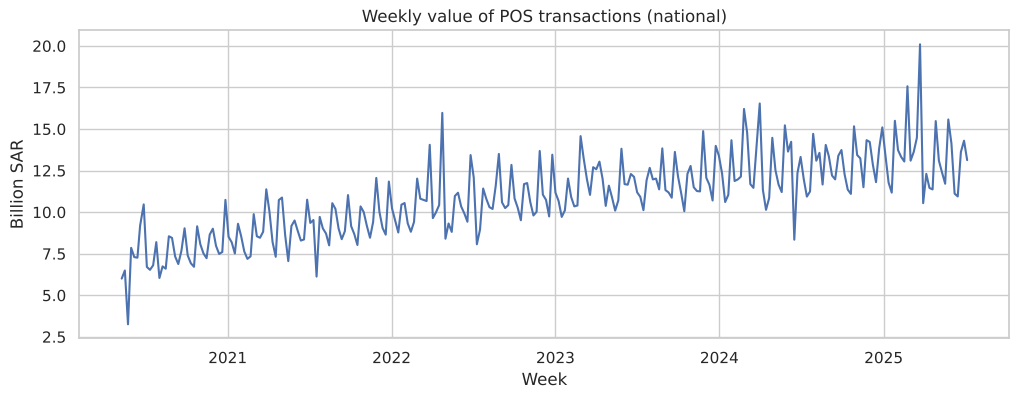

In [ ]:
plt.figure(figsize=(12, 4))
sns.lineplot(data=national, x='date', y=national['value_sar_k'] / 1e6)
plt.title('Weekly value of POS transactions (national)')
plt.xlabel('Week')
plt.ylabel('Billion SAR')
plt.show()

**Insight:** Average weekly spending rose from about SAR 7.6 billion in 2020 to about SAR 13.4 billion in 2025, with strong week-to-week swings. The highest week is in March 2025 (about SAR 20 billion).

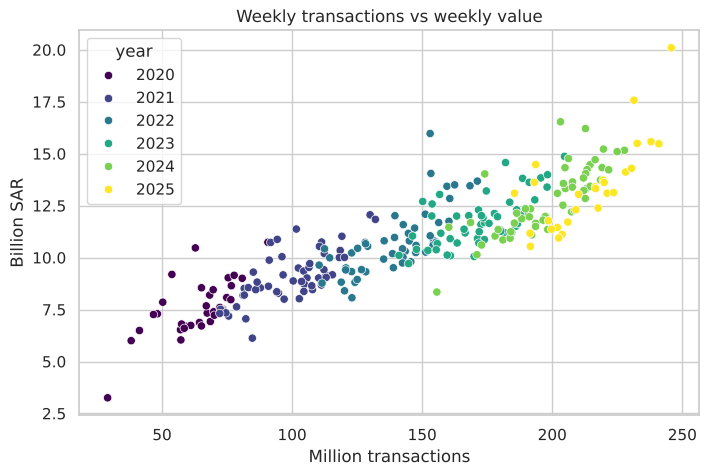

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=national, x=national['transactions_k'] / 1e3, y=national['value_sar_k'] / 1e6, hue='year', palette='viridis')
plt.title('Weekly transactions vs weekly value')
plt.xlabel('Million transactions')
plt.ylabel('Billion SAR')
plt.show()

**Insight:** Spending and transactions rise together: weekly transactions grew from about 40 million to about 225 million. In later years the points sit further to the right than upward, so transactions grew faster than spending. Both series grow with time, so this shows a shared trend, not that one causes the other.

#### 5.3.2 Average ticket over time

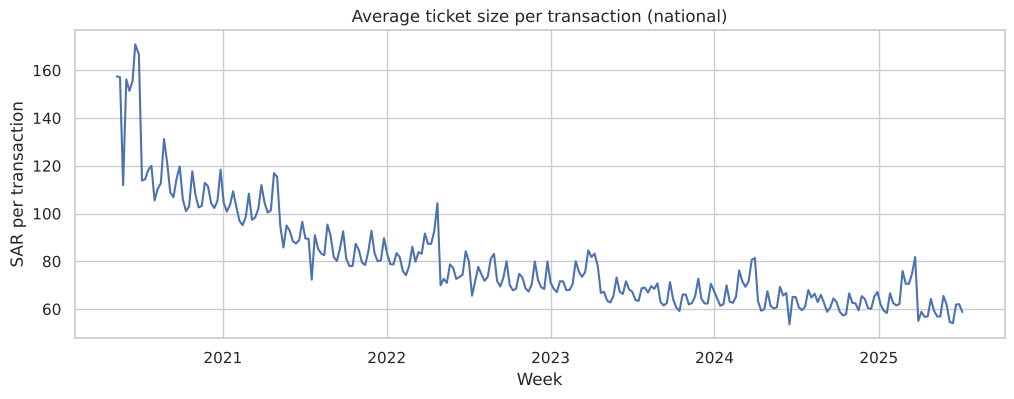

In [ ]:
plt.figure(figsize=(12, 4))
sns.lineplot(data=national, x='date', y='avg_ticket_sar')
plt.title('Average ticket size per transaction (national)')
plt.xlabel('Week')
plt.ylabel('SAR per transaction')
plt.show()

**Insight:** The average ticket fell from about SAR 121 (2020) to about SAR 63 (2025), because transactions grew faster than spending. This is consistent with more frequent, smaller card payments, possibly due to wider use of electronic payments and the recovery after the 2020 lockdown. The data cannot separate these two explanations.

#### 5.3.3 Monthly pattern

In [ ]:
full = national[national['year'].isin(FULL_YEARS)].copy()

# each week as a share of its own year's average (removes the growth trend)
full['relative'] = full['value_sar_k'] / full.groupby('year')['value_sar_k'].transform('mean')

all_weeks = full.groupby('month')['relative'].mean()
no_ramadan = full[full['is_ramadan'] == 0].groupby('month')['relative'].mean()

print(pd.DataFrame({'all_weeks': all_weeks, 'no_ramadan': no_ramadan}).round(3))

       all_weeks  no_ramadan
month                       
1          0.926       0.926
2          0.952       0.952
3          1.055       1.054
4          1.001       0.948
5          0.964       0.950
6          0.995       0.995
7          0.959       0.959
8          1.038       1.038
9          1.016       1.016
10         1.000       1.000
11         1.043       1.043
12         1.062       1.062


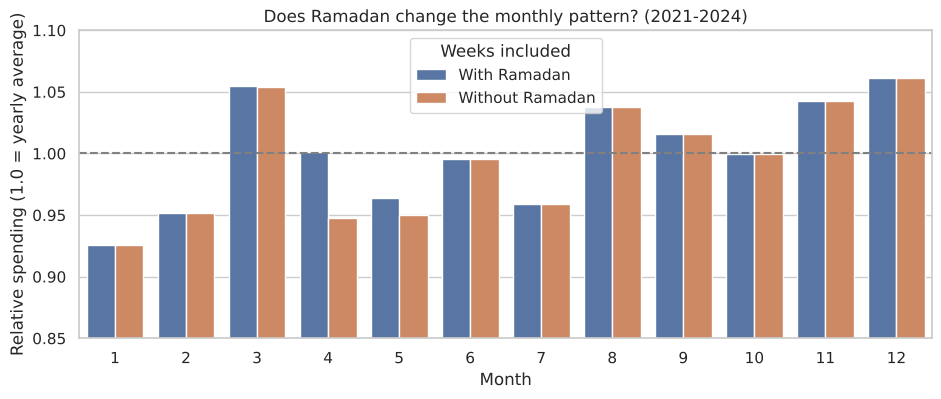

In [ ]:
compare = pd.DataFrame({'With Ramadan': all_weeks, 'Without Ramadan': no_ramadan}).reset_index()
compare = compare.melt(id_vars='month', var_name='Weeks included', value_name='relative')

plt.figure(figsize=(11, 4))
sns.barplot(data=compare, x='month', y='relative', hue='Weeks included')
plt.axhline(1, color='gray', linestyle='--')
plt.title('Does Ramadan change the monthly pattern? (2021-2024)')
plt.xlabel('Month')
plt.ylabel('Relative spending (1.0 = yearly average)')
plt.ylim(0.85, 1.1)
plt.show()

**Insight:** Once the yearly growth trend is removed, spending is lowest in January and highest in December and March. Ramadan does not change the pattern in most months, but it explains April's strength: April drops from 1.00 to 0.95 when Ramadan weeks are excluded.

### 5.4 Sectors

#### 5.4.1 Share of spending by sector

                                   billion_SAR  share_%
name                                                   
Other sector                             356.0     15.4
Beverage and Food                        355.0     15.3
Restaurants & Café                       328.0     14.1
Miscellaneous Goods and Services         252.0     10.9
Clothing and Footwear                    169.0      7.3
Health                                   154.0      6.7
Gas Stations                             148.0      6.4
Transportation                           130.0      5.6
Construction & Building Materials         73.0      3.2
Furniture                                 65.0      2.8
Recreation and Culture                    59.0      2.5
Hotels                                    52.0      2.2
Electronic & Electric Devices             52.0      2.2
Jewelry                                   51.0      2.2
Education                                 35.0      1.5
Telecommunication                         21.0  

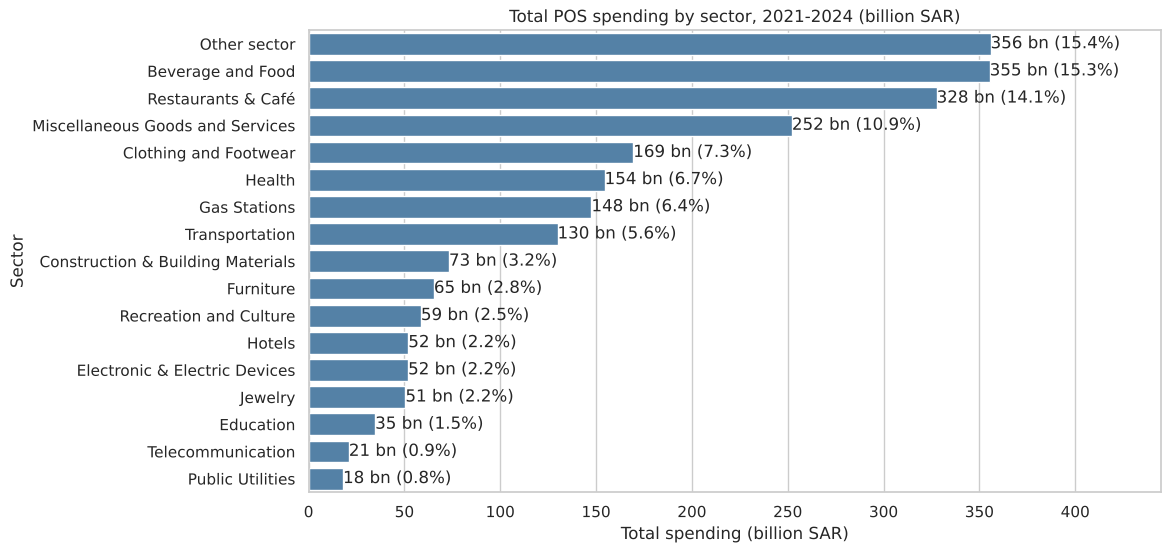

In [ ]:
sector_full = sector[sector['year'].isin(FULL_YEARS)]
sector_total = (sector_full.groupby('name')['value_sar_k'].sum() / 1e6).sort_values(ascending=False)   # billion SAR
sector_share = sector_total / sector_total.sum() * 100
print(pd.DataFrame({'billion_SAR': sector_total.round(0), 'share_%': sector_share.round(1)}))

plt.figure(figsize=(11, 6))
ax = sns.barplot(x=sector_total.values, y=sector_total.index, color='steelblue')
ax.bar_label(ax.containers[0], labels=[f'{v:,.0f} bn ({s:.1f}%)' for v, s in zip(sector_total, sector_share)])
plt.title('Total POS spending by sector, 2021-2024 (billion SAR)')
plt.xlabel('Total spending (billion SAR)')
plt.ylabel('Sector')
plt.xlim(0, sector_total.max() * 1.25)
plt.show()

**Insight:** Spending is concentrated in a few sectors: Other sector (15.4%, unspecified), Beverage and Food (15.3%) and Restaurants & Café (14.1%) each account for about one seventh of spending. Together with Miscellaneous (10.9%), the top four represent about 56%. Everyday categories (food, restaurants, fuel, health) dominate, while telecommunication and public utilities are below 1%.

#### 5.4.2 Average ticket by sector

name
Education                            1486.0
Jewelry                              1075.0
Hotels                                410.0
Furniture                             293.0
Transportation                        292.0
Construction & Building Materials     288.0
Electronic & Electric Devices         275.0
Clothing and Footwear                 148.0
Telecommunication                     141.0
Recreation and Culture                128.0
Health                                105.0
Other sector                           81.0
Public Utilities                       79.0
Miscellaneous Goods and Services       72.0
Gas Stations                           56.0
Beverage and Food                      47.0
Restaurants & Café                     36.0
dtype: float64


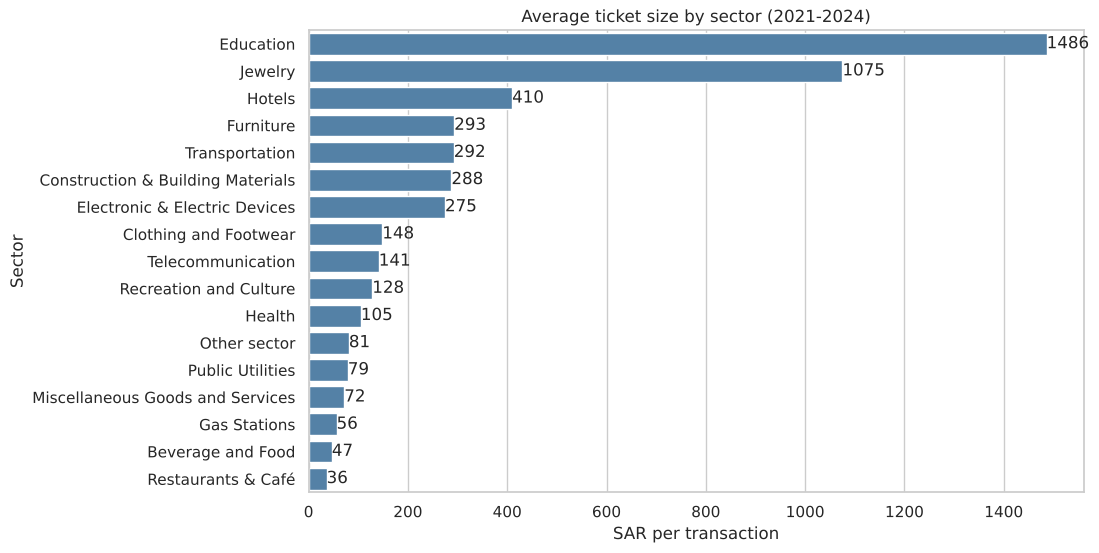

In [ ]:
sector_ticket = sector_full.groupby('name')[['value_sar_k', 'transactions_k']].sum()
sector_ticket = (sector_ticket['value_sar_k'] / sector_ticket['transactions_k']).sort_values(ascending=False)
print(sector_ticket.round(0))
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=sector_ticket.values, y=sector_ticket.index, color='steelblue')
ax.bar_label(ax.containers[0], fmt='%.0f')
plt.title('Average ticket size by sector (2021-2024)')
plt.xlabel('SAR per transaction')
plt.ylabel('Sector')
plt.show()

**Insight:** The average ticket varies about 40-fold across sectors, from SAR 36 (restaurants and cafés) and SAR 47 (food and beverage) to SAR 1,075 (jewelry) and SAR 1,486 (education). Frequent everyday purchases have small tickets, while occasional large purchases (hotels, furniture, jewelry, tuition) have large ones.

#### 5.4.3 Share of spending vs share of transactions

                                   spending_share  transactions_share
name                                                                 
Restaurants & Café                           14.1                28.3
Beverage and Food                            15.3                23.8
Other sector                                 15.4                13.8
Miscellaneous Goods and Services             10.9                11.0
Gas Stations                                  6.4                 8.2
Health                                        6.7                 4.6
Clothing and Footwear                         7.3                 3.6
Recreation and Culture                        2.5                 1.4
Transportation                                5.6                 1.4
Construction & Building Materials             3.2                 0.8
Public Utilities                              0.8                 0.7
Furniture                                     2.8                 0.7
Electronic & Electri

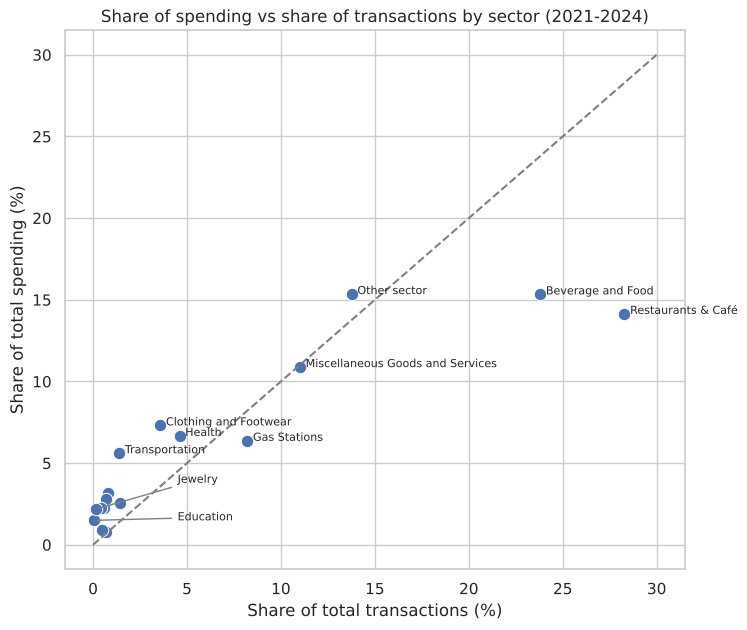

In [ ]:
sector_tx = sector_full.groupby('name')[['value_sar_k', 'transactions_k']].sum()
sector_tx = sector_tx / sector_tx.sum() * 100      # shares (%)
sector_tx.columns = ['spending_share', 'transactions_share']
print(sector_tx.round(1).sort_values('transactions_share', ascending=False))

plt.figure(figsize=(8, 7))
sns.scatterplot(data=sector_tx, x='transactions_share', y='spending_share', s=80)
plt.plot([0, 30], [0, 30], color='gray', linestyle='--')   # equal shares line
for name, row in sector_tx.iterrows():
    if row.max() > 4:   # label the main sectors
        plt.text(row['transactions_share'] + 0.3, row['spending_share'], name, fontsize=8)
for name, pos in {'Jewelry': (4.5, 3.8), 'Education': (4.5, 1.5)}.items():   # small sectors near the origin
    row = sector_tx.loc[name]
    plt.annotate(name, xy=(row['transactions_share'], row['spending_share']), xytext=pos, fontsize=8, arrowprops=dict(arrowstyle='-', color='gray'))
plt.title('Share of spending vs share of transactions by sector (2021-2024)')
plt.xlabel('Share of total transactions (%)')
plt.ylabel('Share of total spending (%)')
plt.show()

**Insight:** Some sectors are large because of many small transactions: restaurants and cafés account for 28% of transactions but 14% of spending, and food and beverage for 24% and 15%. Others are large per transaction: jewelry and education account for about 0.1% of transactions each but about 2% of spending.

#### 5.4.4 Does the month change the sector mix?

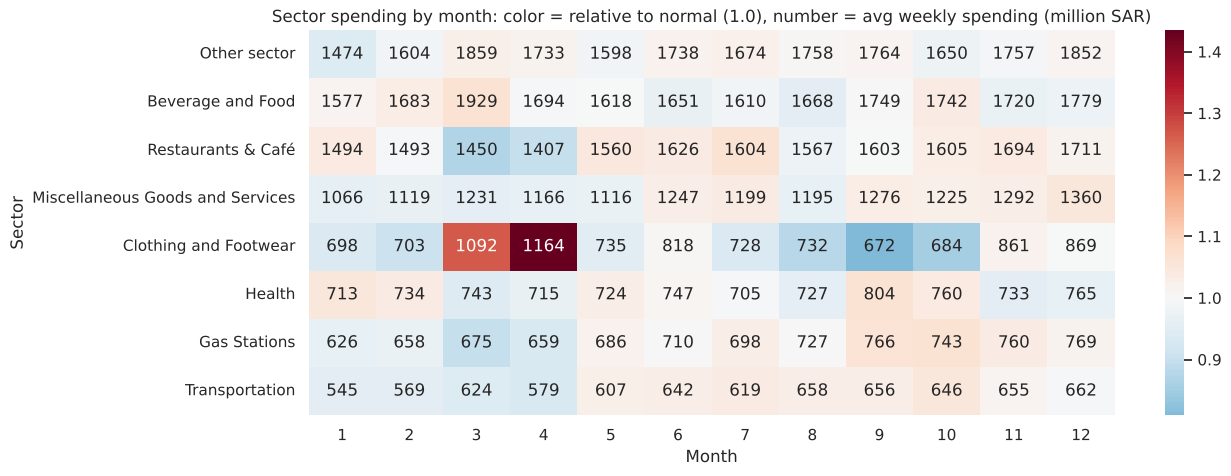

month                               1     2     3     4     5     6     7   \
name                                                                         
Other sector                      0.94  0.98  1.02  1.02  0.99  1.02  1.02   
Beverage and Food                 1.01  1.03  1.06  1.00  1.00  0.97  0.99   
Restaurants & Café                1.04  0.99  0.87  0.90  1.05  1.03  1.06   
Miscellaneous Goods and Services  0.96  0.97  0.96  0.97  0.97  1.03  1.03   
Clothing and Footwear             0.94  0.91  1.26  1.43  0.95  1.01  0.93   
Health                            1.05  1.04  0.94  0.97  1.03  1.01  0.99   
Gas Stations                      0.96  0.97  0.90  0.93  1.02  1.00  1.03   
Transportation                    0.96  0.95  0.94  0.93  1.03  1.03  1.04   

month                               8     9     10    11    12  
name                                                            
Other sector                      1.01  1.01  0.98  0.99  1.01  
Beverage and Food       

In [ ]:
month_sector = sector_full.pivot_table(index='name', columns='month', values='value_sar_k', aggfunc='sum')

# index: sector's share inside each month, divided by its normal share across the year
share_in_month = month_sector / month_sector.sum()
normal_share = month_sector.sum(axis=1) / month_sector.sum().sum()
index_table = share_in_month.div(normal_share, axis=0)

# real amounts: average weekly spending (million SAR)
amounts = sector_full.pivot_table(index='name', columns='month', values='value_sar_k', aggfunc='mean') / 1e3

top8 = sector_share.head(8).index
plt.figure(figsize=(13, 5))
sns.heatmap(index_table.loc[top8], annot=amounts.loc[top8].round(0), fmt='g', cmap='RdBu_r', center=1)
plt.title('Sector spending by month: color = relative to normal (1.0), number = avg weekly spending (million SAR)')
plt.xlabel('Month')
plt.ylabel('Sector')
plt.show()
print(index_table.loc[top8].round(2))   # 1.0 = normal share

**Insight:** The month changes the sector mix. Clothing and footwear peaks in March and April (up to 43% above its normal share, around Ramadan and Eid), while restaurants and cafés fall 10-13% below their normal share in the same months. The other top sectors stay within about 10% of their normal share.

#### 5.4.5 Growth by sector, 2021 to 2024

name
Miscellaneous Goods and Services     86.0
Hotels                               70.0
Other sector                         67.0
Gas Stations                         65.0
Education                            54.0
Restaurants & Café                   54.0
Transportation                       47.0
Beverage and Food                    40.0
Clothing and Footwear                20.0
Telecommunication                    17.0
Health                               16.0
Jewelry                               6.0
Recreation and Culture                4.0
Public Utilities                     -7.0
Construction & Building Materials    -7.0
Furniture                            -8.0
Electronic & Electric Devices       -24.0
dtype: float64


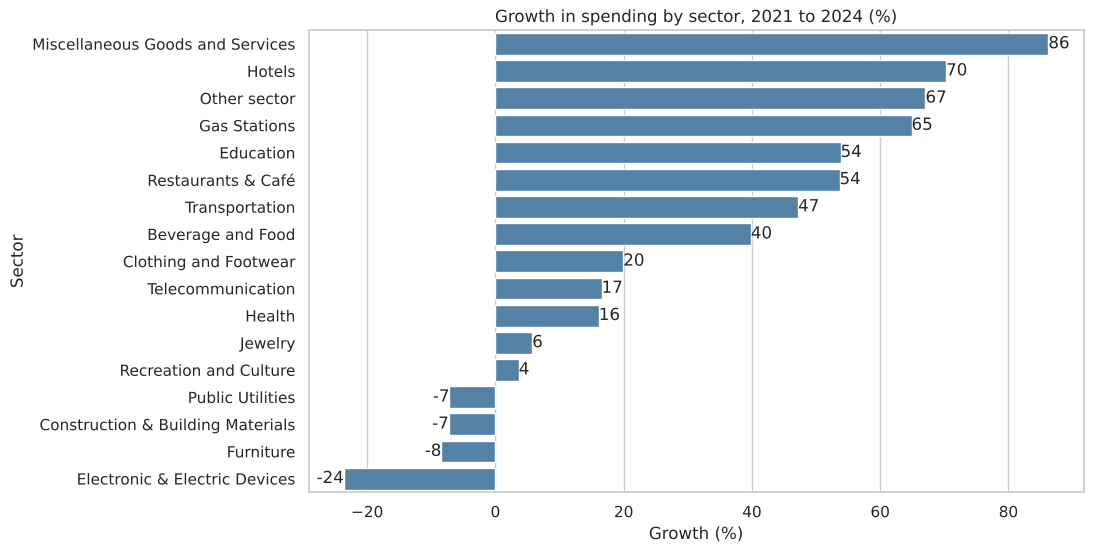

In [ ]:
by_year = sector[sector['year'].isin([2021, 2024])].groupby(['name', 'year'])['value_sar_k'].sum().unstack()
growth = ((by_year[2024] / by_year[2021] - 1) * 100).sort_values(ascending=False)
print(growth.round(0))

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=growth.values, y=growth.index, color='steelblue')
ax.bar_label(ax.containers[0], fmt='%.0f')
plt.title('Growth in spending by sector, 2021 to 2024 (%)')
plt.xlabel('Growth (%)')
plt.ylabel('Sector')
plt.show()

**Insight:** Spending grew in most sectors between 2021 and 2024, fastest in miscellaneous goods and services (+86%), hotels (+70%) and gas stations (+65%). Four sectors shrank: electronics (-24%), furniture (-8%), public utilities and construction (-7% each). Values are nominal, so part of the growth reflects higher prices.

#### 5.4.6 Weekly volatility by sector

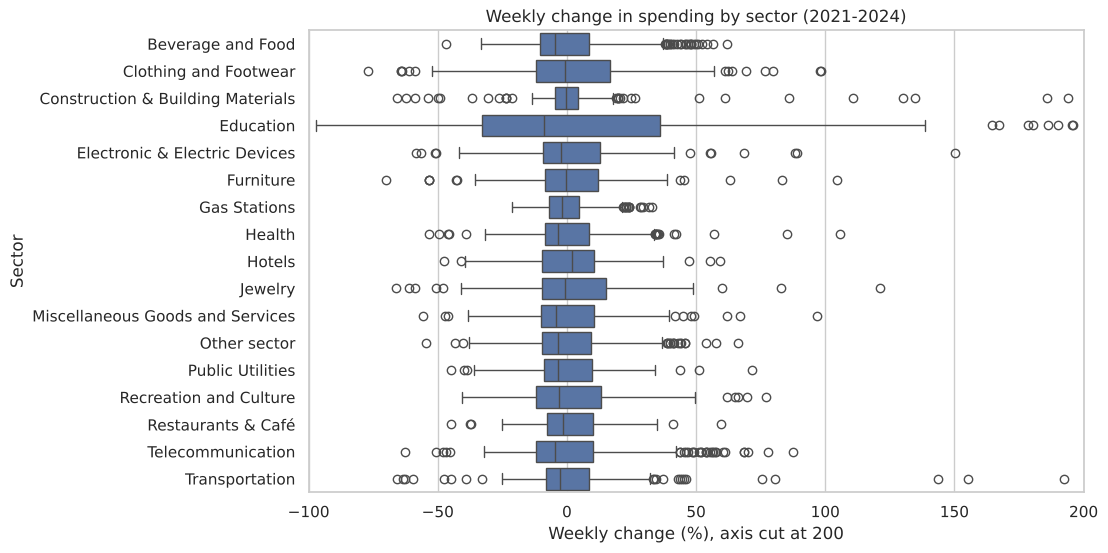

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=sector[sector['year'].isin(FULL_YEARS)], x='value_change_pct', y='name')
plt.xlim(-100, 200)
plt.title('Weekly change in spending by sector (2021-2024)')
plt.xlabel('Weekly change (%), axis cut at 200')
plt.ylabel('Sector')
plt.show()

**Insight:** Most sectors show similar week-to-week variability. Education is the clear exception: weekly changes reach about +3,000% (the axis is cut at 200), consistent with tuition payments concentrated in a few weeks around the school year. These extreme weeks were kept because they are real, not errors.

### 5.5 Cities

#### 5.5.1 Spending by city

              billion_SAR  share_%
name                              
Riyadh              746.0     32.2
Other cities        687.0     29.7
Jeddah              345.0     14.9
Dammam              119.0      5.1
Makkah               91.0      3.9
Madinah              90.0      3.9
Khobar               70.0      3.0
Buraidah             56.0      2.4
Tabuk                43.0      1.9
Hail                 38.0      1.6
Abha                 33.0      1.4


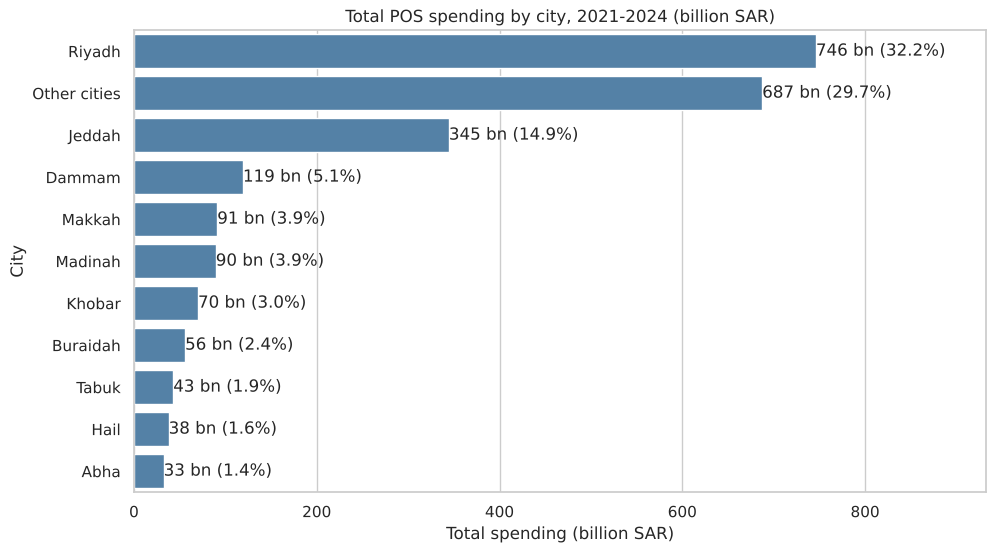

In [ ]:
city_full = city[city['year'].isin(FULL_YEARS)]
city_total = (city_full.groupby('name')['value_sar_k'].sum() / 1e6).sort_values(ascending=False)   # billion SAR
city_share = city_total / city_total.sum() * 100
print(pd.DataFrame({'billion_SAR': city_total.round(0), 'share_%': city_share.round(1)}))

plt.figure(figsize=(11, 6))
ax = sns.barplot(x=city_total.values, y=city_total.index, color='steelblue')
ax.bar_label(ax.containers[0], labels=[f'{v:,.0f} bn ({s:.1f}%)' for v, s in zip(city_total, city_share)])
plt.title('Total POS spending by city, 2021-2024 (billion SAR)')
plt.xlabel('Total spending (billion SAR)')
plt.ylabel('City')
plt.xlim(0, city_total.max() * 1.25)
plt.show()

**Insight:** Spending is concentrated in the largest cities: Riyadh (32%) and Jeddah (15%) together account for almost half of spending, and "Other cities" (a group of smaller cities) for another 30%. Makkah and Madinah each represent only about 4%.

#### 5.5.2 Transactions by city

              million_transactions  share_%
name                                       
Other cities               11148.0     35.0
Riyadh                      9294.0     29.2
Jeddah                      4063.0     12.8
Dammam                      1384.0      4.3
Madinah                     1361.0      4.3
Makkah                      1326.0      4.2
Buraidah                     763.0      2.4
Khobar                       722.0      2.3
Tabuk                        686.0      2.2
Hail                         584.0      1.8
Abha                         518.0      1.6


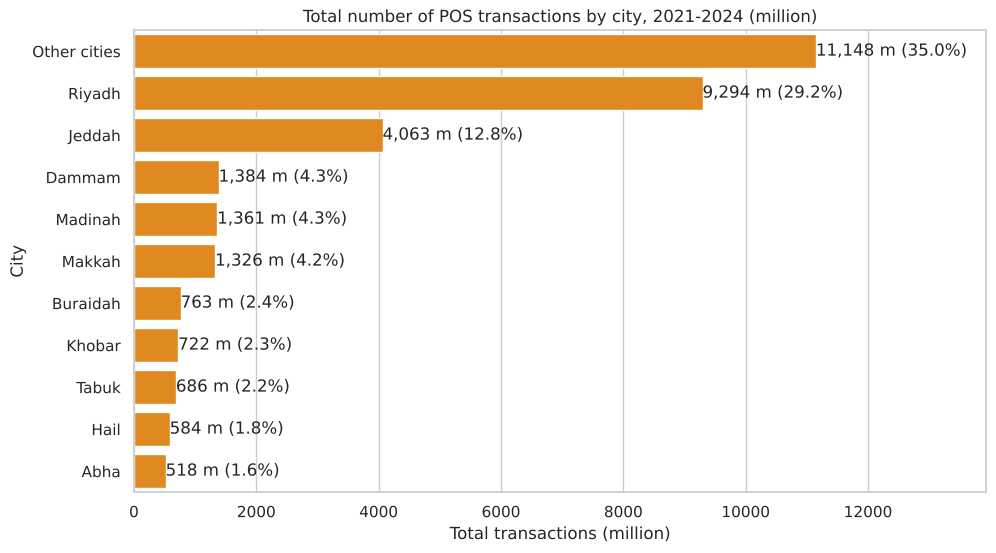

In [ ]:
city_tx = (city_full.groupby('name')['transactions_k'].sum() / 1e3).sort_values(ascending=False)   # million transactions
city_tx_share = city_tx / city_tx.sum() * 100
print(pd.DataFrame({'million_transactions': city_tx.round(0), 'share_%': city_tx_share.round(1)}))

plt.figure(figsize=(11, 6))
ax = sns.barplot(x=city_tx.values, y=city_tx.index, color='darkorange')
ax.bar_label(ax.containers[0], labels=[f'{v:,.0f} m ({s:.1f}%)' for v, s in zip(city_tx, city_tx_share)])
plt.title('Total number of POS transactions by city, 2021-2024 (million)')
plt.xlabel('Total transactions (million)')
plt.ylabel('City')
plt.xlim(0, city_tx.max() * 1.25)
plt.show()

**Insight:** Transaction counts follow a similar ranking, but Riyadh (29% of transactions vs 32% of spending) and Jeddah (13% vs 15%) have a smaller share of transactions than of spending, while "Other cities" have a larger one (35% vs 30%).

#### 5.5.3 Average ticket by city

name
Khobar          97.0
Dammam          86.0
Jeddah          85.0
Riyadh          80.0
Buraidah        73.0
Makkah          69.0
Madinah         66.0
Hail            65.0
Abha            63.0
Tabuk           63.0
Other cities    62.0
dtype: float64


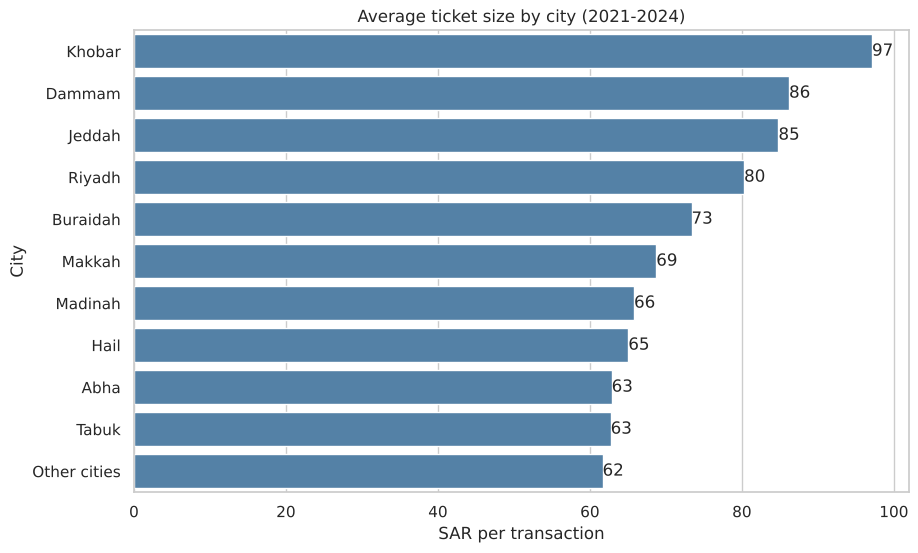

In [ ]:
city_ticket = city_full.groupby('name')[['value_sar_k', 'transactions_k']].sum()
city_ticket = (city_ticket['value_sar_k'] / city_ticket['transactions_k']).sort_values(ascending=False)
print(city_ticket.round(0))

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=city_ticket.values, y=city_ticket.index, color='steelblue')
ax.bar_label(ax.containers[0], fmt='%.0f')
plt.title('Average ticket size by city (2021-2024)')
plt.xlabel('SAR per transaction')
plt.ylabel('City')
plt.show()

**Insight:** The average ticket differs only modestly across cities, from SAR 62 (other cities) to SAR 97 (Khobar); Riyadh is fourth (SAR 80). The four largest urban centres (Khobar, Dammam, Jeddah, Riyadh) have the highest tickets. The data has no sector-by-city breakdown, so the cause cannot be identified.

#### 5.5.4 Weekly volatility by city

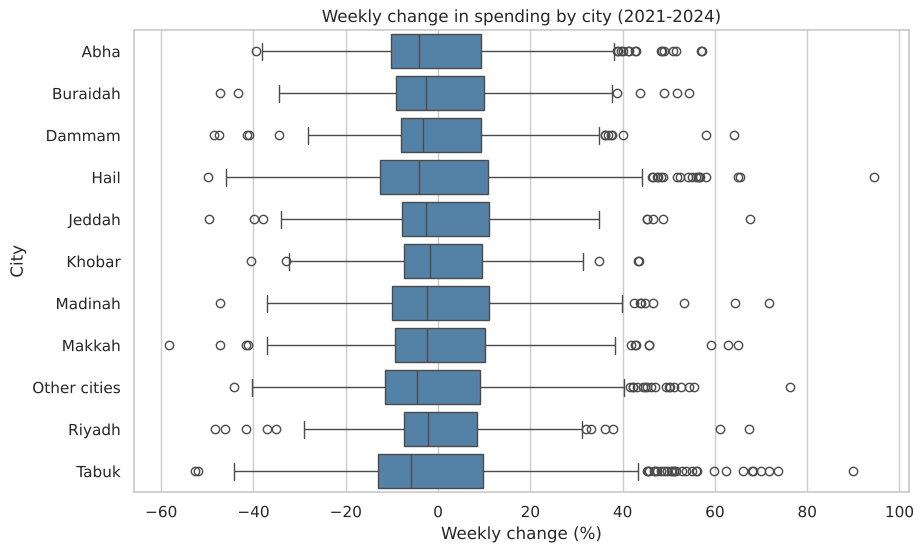

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=city_full, x='value_change_pct', y='name', color='steelblue')
plt.title('Weekly change in spending by city (2021-2024)')
plt.xlabel('Weekly change (%)')
plt.ylabel('City')
plt.show()

**Insight:** Weekly spending is more volatile in smaller cities (Tabuk, Hail) than in the largest ones (Riyadh, Jeddah, Khobar), as expected: a smaller base moves more with each holiday or large purchase. In all cities the median weekly change is slightly negative, with occasional large positive spikes. These weeks were kept because they match holidays, not errors.

### 5.6 Correlation heatmap

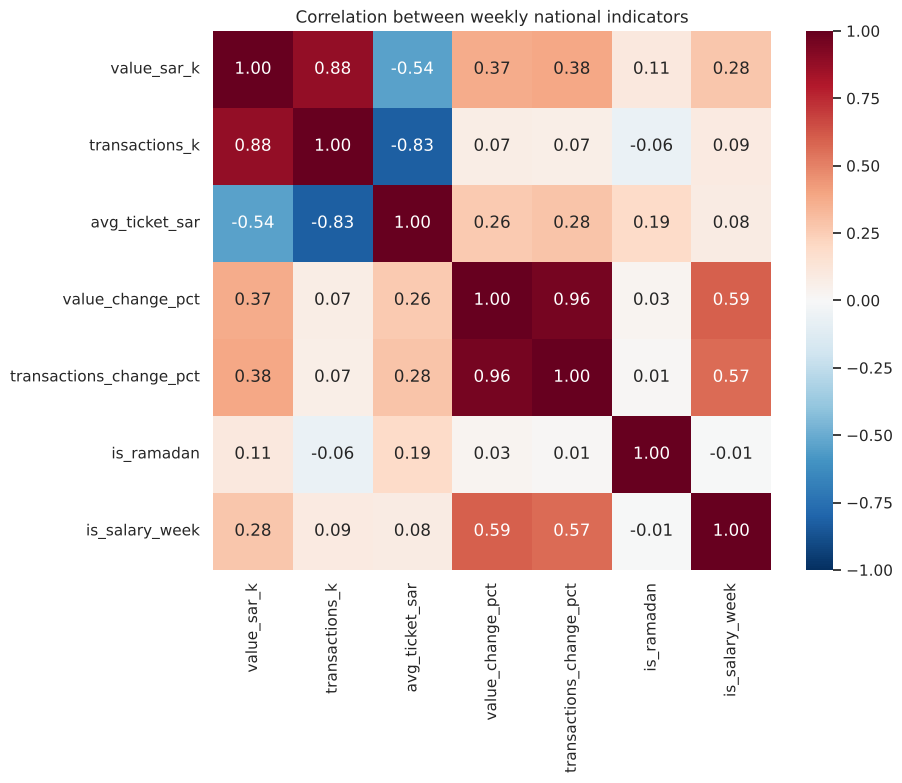

In [ ]:
corr_cols = ['value_sar_k', 'transactions_k', 'avg_ticket_sar', 'value_change_pct',
             'transactions_change_pct', 'is_ramadan', 'is_salary_week']
plt.figure(figsize=(9, 7))
sns.heatmap(national[corr_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation between weekly national indicators')
plt.show()

**Insight:** Spending and transactions move together (0.88), and the average ticket moves against transactions (-0.83): more payments came with smaller payments. These relationships are partly a shared time trend, because all three series change over the years, so they describe patterns and not cause and effect. The weekly change in spending is linked to salary weeks (0.59), while the Ramadan flag is weakly related to everything (at most 0.19): the Ramadan effect depends on the sector and is hidden in the national total (see H1 below).

### 5.7 Hypotheses

Each hypothesis compares an **event week** with the **four weeks before and four weeks after** it, excluding other event weeks, so that a holiday is not compared with an unrelated quiet period. Results are averaged over the four full years (2021-2024) unless stated otherwise.

In [ ]:
def compare_event(table, flag):
    table = table.sort_values('date').reset_index(drop=True)
    is_event = table[flag] == 1
    event_id = (is_event != is_event.shift()).cumsum()

    rows = []
    for _, event in table[is_event].groupby(event_id[is_event]):
        first, last = event.index.min(), event.index.max()
        around = pd.concat([table.loc[max(0, first - 4):first - 1],
                            table.loc[last + 1:last + 4]])
        around = around[around[flag] == 0]

        rows.append({
            'start': event['date'].min().date(),
            'year': event['date'].min().year,
            'value_change_%': (event['value_sar_k'].mean() / around['value_sar_k'].mean() - 1) * 100,
            'transactions_change_%': (event['transactions_k'].mean() / around['transactions_k'].mean() - 1) * 100,
            'ticket_change_%': (event['avg_ticket_sar'].mean() / around['avg_ticket_sar'].mean() - 1) * 100,
        })
    return pd.DataFrame(rows).round(1)

#### H1: Do restaurants and cafés spend more during Ramadan?

Common belief: restaurant spending rises during Ramadan. We compare Ramadan weeks with the four weeks before and after, for restaurants, for food and beverage shops, and for all sectors.

scope  All sectors (national)  Beverage and Food  Restaurants & Café
year                                                                
2021                     -0.1               -4.4               -22.8
2022                      9.9               -7.4               -25.0
2023                      7.3               -5.0               -16.8
2024                      5.4               -1.1               -23.9
                        value_change_%  transactions_change_%  ticket_change_%
scope                                                                         
All sectors (national)             5.6                   -7.8             14.4
Beverage and Food                 -4.5                   -5.4              1.2
Restaurants & Café               -22.1                  -30.0             10.1


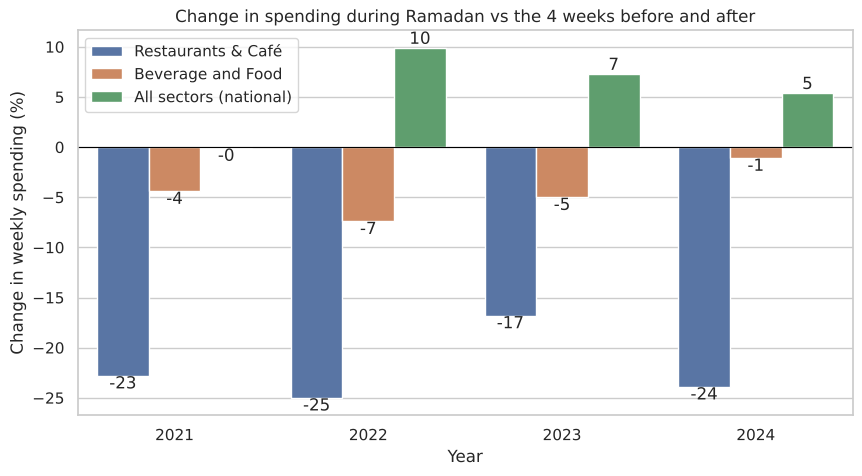

In [ ]:
scopes = {
    'Restaurants & Café': sector[sector['name'] == 'Restaurants & Café'],
    'Beverage and Food': sector[sector['name'] == 'Beverage and Food'],
    'All sectors (national)': national,
}

results = []
for name, table in scopes.items():
    r = compare_event(table, 'is_ramadan')
    r['scope'] = name
    results.append(r)

h1 = pd.concat(results)
h1 = h1[h1['year'].isin(FULL_YEARS)]

print(h1.pivot(index='year', columns='scope', values='value_change_%'))
print(h1.groupby('scope')[['value_change_%', 'transactions_change_%', 'ticket_change_%']].mean().round(1))

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=h1, x='year', y='value_change_%', hue='scope')
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Change in spending during Ramadan vs the 4 weeks before and after')
plt.xlabel('Year')
plt.ylabel('Change in weekly spending (%)')
plt.legend(title='')
plt.show()

**Insight:** Contrary to the common belief, spending at restaurants and cafés falls during Ramadan: on average 22% lower than in the four weeks before and after (and 30% fewer transactions), in each of the four years. Food and beverage shops fall only slightly (-4.5%), and total spending rises (+5.6%). **H1 is not supported.** Across all sectors, Ramadan means fewer but larger payments: transactions fall about 8% while the average ticket rises about 14%.

#### H2: Do people spend more in the week salaries are paid?

Assumption: salaries are paid around the 27th of each month, so a "salary week" is a week that contains the 27th. We compare each salary week with the surrounding weeks, and split the change into transactions and average ticket.

                        value_change_%  transactions_change_%  ticket_change_%
scope                                                                         
All sectors (national)            13.1                    5.1              7.5
Beverage and Food                 19.4                    3.7             14.7
Clothing and Footwear             18.6                   15.8              2.7
Gas Stations                       7.5                    4.0              3.2
Restaurants & Café                 7.2                    3.2              3.7
scope
All sectors (national)    48
Beverage and Food         48
Clothing and Footwear     48
Gas Stations              48
Restaurants & Café        48
dtype: int64
week_type  Other weeks  Salary week
year                               
2021              8.84         9.92
2022             10.14        12.63
2023             11.53        12.59
2024             12.57        13.48


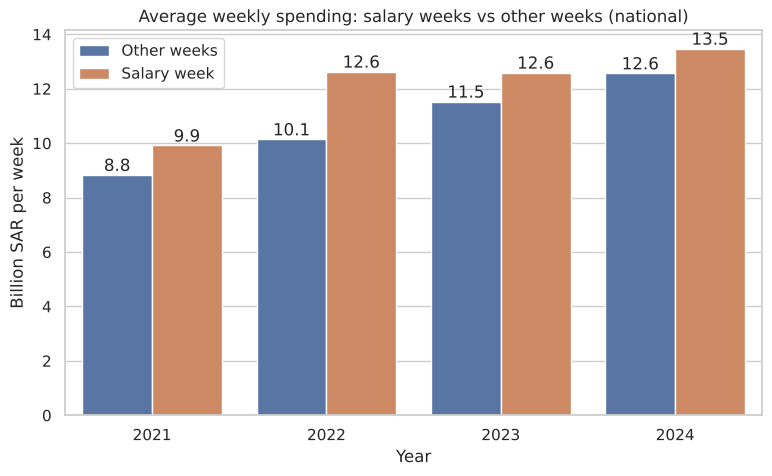

In [ ]:
salary_scopes = {
    'All sectors (national)': national,
    'Beverage and Food': sector[sector['name'] == 'Beverage and Food'],
    'Clothing and Footwear': sector[sector['name'] == 'Clothing and Footwear'],
    'Restaurants & Café': sector[sector['name'] == 'Restaurants & Café'],
    'Gas Stations': sector[sector['name'] == 'Gas Stations'],
}

results = []
for name, table in salary_scopes.items():
    r = compare_event(table, 'is_salary_week')
    r['scope'] = name
    results.append(r)

h2 = pd.concat(results)
h2 = h2[h2['year'].isin(FULL_YEARS)]

h2_summary = h2.groupby('scope')[['value_change_%', 'transactions_change_%', 'ticket_change_%']].mean().round(1)
print(h2_summary)
print(h2.groupby('scope').size())   # number of salary weeks per scope

salary_compare = national[national['year'].isin(FULL_YEARS)].copy()
salary_compare['week_type'] = salary_compare['is_salary_week'].map({1: 'Salary week', 0: 'Other weeks'})

weekly_avg = (salary_compare.groupby(['year', 'week_type'])['value_sar_k'].mean() / 1e6).reset_index()
print(weekly_avg.pivot(index='year', columns='week_type', values='value_sar_k').round(2))

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=weekly_avg, x='year', y='value_sar_k', hue='week_type', hue_order=['Other weeks', 'Salary week'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f')
plt.title('Average weekly spending: salary weeks vs other weeks (national)')
plt.xlabel('Year')
plt.ylabel('Billion SAR per week')
plt.legend(title='')
plt.show()

**Insight:** In each of the four years, average weekly spending is higher in salary weeks than in other weeks (by about 7% to 25%). Against the surrounding weeks, salary weeks are about 13% higher nationally (48 salary weeks), through both more transactions (+5%) and a larger ticket (+7.5%). Clothing rises mainly through more transactions (+16%), food and beverage through a larger ticket (+15%).

week_start_day
1-6       2.6
7-13     -3.6
14-20    -9.9
21-27    10.1
28-31    13.1
Name: deviation_%, dtype: float64


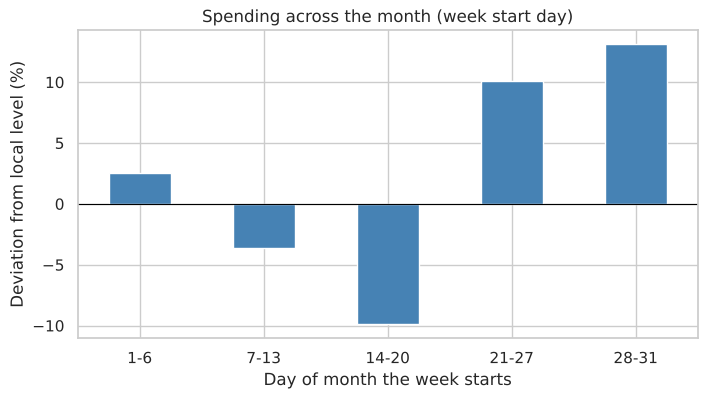

In [ ]:
nat = national.sort_values('date').reset_index(drop=True)
nat['deviation_%'] = (nat['value_sar_k'] / nat['value_sar_k'].rolling(9, center=True, min_periods=5).median() - 1) * 100

cycle = nat[(nat['year'].between(2021, 2024)) & (nat['is_ramadan'] == 0)].copy()
cycle['week_start_day'] = pd.cut(cycle['date'].dt.day, [0, 6, 13, 20, 27, 31],
                                 labels=['1-6', '7-13', '14-20', '21-27', '28-31'])
by_cycle = cycle.groupby('week_start_day', observed=True)['deviation_%'].mean()
print(by_cycle.round(1))

by_cycle.plot(kind='bar', figsize=(8, 4), color='steelblue')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Spending across the month (week start day)')
plt.xlabel('Day of month the week starts')
plt.ylabel('Deviation from local level (%)')
plt.xticks(rotation=0)
plt.show()

**Insight:** Spending follows a monthly cycle (Ramadan weeks excluded): weeks starting in mid-month (14th-20th) are about 10% below the local level, while weeks starting from the 21st to the end of the month are 10-13% above it. This is consistent with salaries paid around the 27th, which is an assumption and not a verified payday.

#### H3: Do Makkah and Madinah rise more than other cities during Ramadan?

Common belief: the holy cities see a surge in spending during Ramadan (Umrah and visitors). We compare Makkah and Madinah with Jeddah and Riyadh.

city  Jeddah  Madinah  Makkah  Riyadh
year                                 
2021     1.7      8.2    36.7    -3.9
2022    15.0     21.1    72.5     4.9
2023    10.2     19.7    58.2     3.0
2024     7.8     10.7    46.6     3.0
         value_change_%  transactions_change_%  ticket_change_%
city                                                           
Jeddah              8.7                   -5.6             14.8
Madinah            14.9                   -2.4             17.0
Makkah             53.5                   10.2             39.1
Riyadh              1.8                  -10.8             14.1


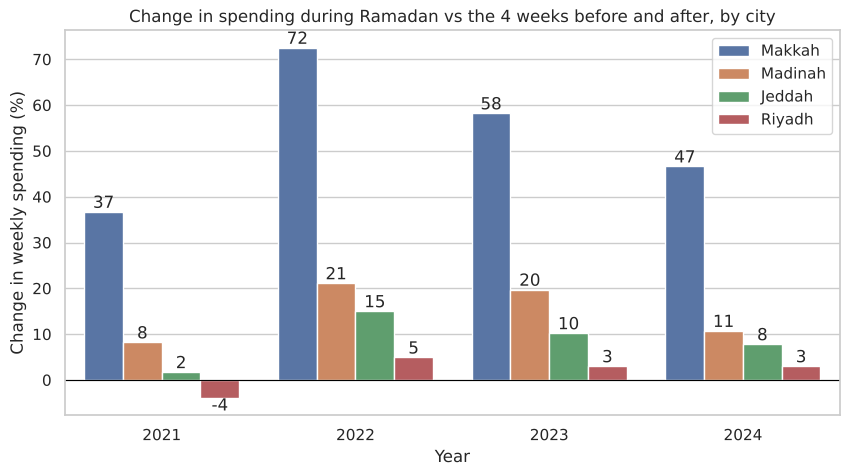

In [ ]:
cities_to_compare = ['Makkah', 'Madinah', 'Jeddah', 'Riyadh']

results = []
for name in cities_to_compare:
    r = compare_event(city[city['name'] == name], 'is_ramadan')
    r['city'] = name
    results.append(r)

h3 = pd.concat(results)
h3 = h3[h3['year'].isin(FULL_YEARS)]

print(h3.pivot(index='year', columns='city', values='value_change_%'))
print(h3.groupby('city')[['value_change_%', 'transactions_change_%', 'ticket_change_%']].mean().round(1))


plt.figure(figsize=(10, 5))
ax = sns.barplot(data=h3, x='year', y='value_change_%', hue='city', hue_order=cities_to_compare)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Change in spending during Ramadan vs the 4 weeks before and after, by city')
plt.xlabel('Year')
plt.ylabel('Change in weekly spending (%)')
plt.legend(title='')
plt.show()

**Insight:** Spending in Makkah rises sharply during Ramadan (+54% on average, between +37% and +73% across the four years), and is the only city where the number of transactions also rises (+10%). Madinah also rises (+15%), while Jeddah (+9%) and Riyadh (+2%) show only small changes. This is consistent with the effect of Umrah and visitors in the holy cities.

#### H4: How does Eid al-Fitr change spending?

Week 0 is the week that contains Eid day. We compare the weeks around Eid (-3 to +2) with normal weeks, for all sectors and for selected sectors. Eid dates are the first day of Eid al-Fitr as announced in Saudi Arabia (2021-2025).

      All sectors (national)  Clothing and Footwear  Jewelry  \
week                                                           
-3                      -8.0                   47.0     18.0   
-2                       5.0                  103.0     68.0   
-1                      28.0                  191.0    168.0   
 0                     -13.0                   29.0     56.0   
 1                     -17.0                  -37.0     -8.0   
 2                     -12.0                  -31.0     -8.0   

      Restaurants & Café  Hotels  
week                              
-3                 -30.0     4.0  
-2                 -21.0    25.0  
-1                   1.0    32.0  
 0                  18.0    17.0  
 1                  -1.0    -9.0  
 2                  -2.0    -9.0  


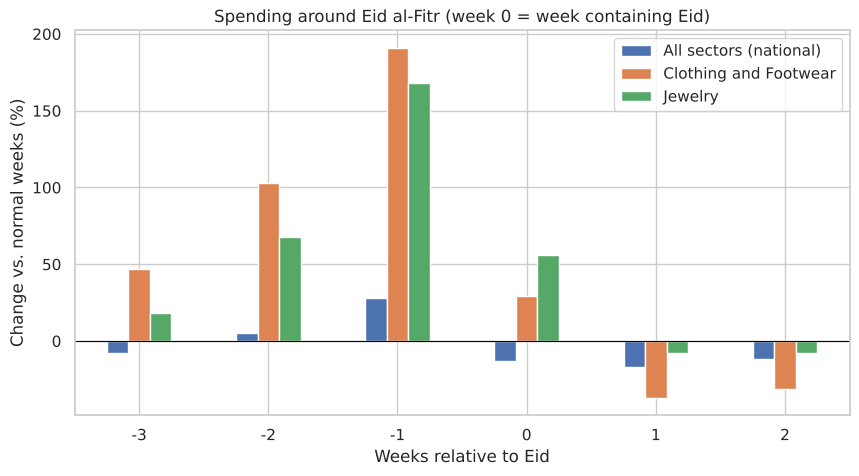

In [ ]:
eid_fitr = ['2021-05-13', '2022-05-02', '2023-04-21', '2024-04-10', '2025-03-30']

def eid_profile(table, eid_dates, col='value_sar_k'):
    table = table.sort_values('date').reset_index(drop=True)
    rows = []
    for d in eid_dates:
        d = pd.Timestamp(d)
        i = table.index[(table['date'] <= d) & (table['date'] + pd.Timedelta(days=6) >= d)][0]
        base = pd.concat([table.loc[i - 6:i - 4], table.loc[i + 3:i + 5]])[col].mean()
        for k in range(-3, 3):
            rows.append({'eid': d.year, 'week': k, 'change_%': (table.loc[i + k, col] / base - 1) * 100})
    return pd.DataFrame(rows)

eid_scopes = {
    'All sectors (national)': national,
    'Clothing and Footwear': sector[sector['name'] == 'Clothing and Footwear'],
    'Jewelry': sector[sector['name'] == 'Jewelry'],
    'Restaurants & Café': sector[sector['name'] == 'Restaurants & Café'],
    'Hotels': sector[sector['name'] == 'Hotels'],
}

eid_results = {}
for name, table in eid_scopes.items():
    p = eid_profile(table, eid_fitr)
    eid_results[name] = p.groupby('week')['change_%'].mean()

h4 = pd.DataFrame(eid_results).round(0)
print(h4)

h4[['All sectors (national)', 'Clothing and Footwear', 'Jewelry']].plot(kind='bar', figsize=(10, 5))
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Spending around Eid al-Fitr (week 0 = week containing Eid)')
plt.xlabel('Weeks relative to Eid')
plt.ylabel('Change vs. normal weeks (%)')
plt.xticks(rotation=0)
plt.show()

**Insight:** The week before Eid al-Fitr is the peak: total spending is 28% above normal, and clothing and footwear (+191%) and jewelry (+168%) are far above normal. Spending then falls below normal for two weeks after Eid. Restaurants and cafés follow a different path: they are 21-30% below normal three to two weeks before Eid (Ramadan) and recover only in the week of Eid (+18%).

## Step 6: Insights summary

**Patterns discovered**
- **Card activity grew strongly.** Average weekly spending rose from about SAR 7.6 billion (2020) to about SAR 13.4 billion (2025), and weekly transactions from about 40 million (May 2020) to about 225 million (mid-2025). The average ticket fell from SAR 121 to SAR 63, consistent with more frequent, smaller card payments.
- **Spending is concentrated.** Four sectors make up about 56% of spending, and Riyadh and Jeddah about 47%. Restaurants and food are large because of many small transactions; jewelry and education because of large ones.
- **There is a monthly pay cycle.** Salary weeks are about 13% higher than the surrounding weeks, and spending is lowest in mid-month.
- **Eid al-Fitr reshapes spending.** The week before Eid is the peak (total +28%, clothing +191%, jewelry +168%), followed by two weak weeks.

**Interesting relationships**
- **Restaurants and cafés spend less in Ramadan, not more** (about 22% less, with 30% fewer transactions, in every year), while total spending rises about 6%. Nationally, Ramadan means fewer, larger payments: transactions fall about 8% and the average ticket rises about 14%.
- **The holy cities rise most in Ramadan:** Makkah +54% (Madinah +15%, Jeddah +9%, Riyadh +2%), although each holds only about 4% of total spending.
- **Transactions and average ticket move in opposite directions** (correlation -0.83), while spending and transactions move together (0.88).

**Outliers**
- Ten weeks fall outside the usual range of weekly change (below -39.5% or above +41.8%). All are in or next to Ramadan, Eid al-Fitr or Eid al-Adha weeks, or in May 2020. They are real weeks and were kept.
- The average ticket is above SAR 100 in 48 weeks, almost all between May 2020 and May 2021, when few transactions were made.

**Key takeaways**
1. Card spending grew mainly because people pay more often, not because each payment became larger.
2. Timing matters: Ramadan, Eid and the pay cycle change spending in clear and different ways for each sector and city.
3. A national total can hide opposite movements, such as restaurants falling while total spending rises in Ramadan.

## Step 7: Limitations and recommendations

**Limitations**
- Card (POS) payments only; cash, transfers and online payments are not included.
- Values are nominal (no inflation adjustment); the VAT increase from 5% to 15% in July 2020 affects early values.
- The data starts in May 2020, after the strictest lockdown, so the impact of the pandemic cannot be measured. 2020 and 2025 are partial years.
- There is no sector-by-city breakdown and no demographic data. The "Other" categories are large (about 15% of sector spending and 30% of city spending).
- Event dates (Ramadan, Eid, salary on the 27th) are assumptions or taken from news sources, and the results are descriptive, not causal.

**Recommendations**
- Retailers: prepare stock and staff for clothing, jewelry and gifts about two weeks before Eid al-Fitr.
- Restaurants and cafés: expect lower traffic in the weeks of Ramadan and a recovery in the week of Eid.
- Marketing teams: concentrate promotions in the second half of the month, around salary weeks.
- Future work: add inflation-adjusted values and sector-by-city data.

**Dashboard:** `app.py` (Streamlit) reads `clean_data.csv` and shows the national, sector and city views with filters for years, measure, sectors and cities, and the findings of Step 5.7.
link: https://kjvas5auwmrsrtzpw7xioh.streamlit.app/